# Thornbury & Co., Customer Lifetime Value Analysis

**Scenario:** Thornbury & Co. is a UK-based online gift and home accessories retailer operating 2010–2011. The company grew rapidly by running deep-discount flash sales alongside an organic editorial newsletter channel. Marketing now has a **£500K win-back budget** and needs to know which customers to target.

**Three things we need to answer:**
1. **Who will buy again?**: cohort retention tells us which acquisition cohorts are genuinely loyal
2. **How much are they worth?**: BG/NBD + Gamma-Gamma produces a 12-month discounted CLV per customer
3. **Which channel should get the budget?**: disaggregating CLV by acquisition channel reveals a critical conflict between the RFM M-score and the probabilistic model

**The guardrail:** Month-1 cohort retention must stay ≥ 20%. Any acquisition strategy that pushes a channel's month-1 retention below this threshold is self-defeating, regardless of how the AOV looks on paper.

---

**Sections:**
1. Setup & Data Loading
2. Channel Structure and Data Distributions
3. Cohort Retention Analysis
4. Guardrail Check, Month-1 Retention by Channel
5. RFM Segmentation
6. BG/NBD Purchase Frequency Model
7. Gamma-Gamma Spend Model
8. 12-Month CLV Prediction
9. The Tension, Monetary Score vs Predicted CLV
10. Holdout Validation
11. Disaggregated CLV by Channel
12. Win-Back Campaign ROI
13. Decision and Recommendation
14. Export Results

In [1]:
import sys, yaml, json
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src.clv.etl import (
    load_synthetic, load_uci_online_retail,
    split_calibration_holdout, to_summary, get_customer_channels,
)
from src.clv.rfm import compute_rfm, umap_cluster, segment_summary, rfm_channel_profile
from src.clv.bgf import (
    fit_bgnbd, fit_gamma_gamma, predict_clv, clv_summary_stats,
    clv_by_channel, holdout_comparison, campaign_roi_by_channel,
)
from src.clv.cohorts import (
    build_retention_matrix, cohort_revenue_matrix,
    retention_by_channel, month1_retention_summary,
)
from src.clv.visualise import (
    plot_retention_heatmap, plot_clv_distribution,
    plot_segment_bar, plot_umap_scatter,
    plot_channel_clv_boxplot, plot_rfm_vs_clv_tension,
    plot_month1_retention_by_channel, plot_holdout_validation,
    plot_campaign_roi, plot_bgnbd_matrices,
)

OUTPUTS = ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)

cfg = yaml.safe_load((ROOT / 'config' / 'default.yaml').read_text())
sns.set_theme(style='whitegrid')
print('Config loaded.')
print(f"  Scenario: {cfg['scenario']['name']}")
print(f"  Channels: {cfg['scenario']['channels']}")
print(f"  Win-back budget: £{cfg['campaign']['win_back_budget']:,}")

Config loaded.
  Scenario: Thornbury & Co.
  Channels: ['Enthusiast', 'Mainstream', 'Deal-Seeker']
  Win-back budget: £500,000


## 1. Load Data

The synthetic generator creates three structurally distinct customer groups driven by a latent `engagement_score`. This score simultaneously determines purchase rate (positive correlation), basket size (negative, low-engagement Deal-Seekers buy less often but spend more per visit), and churn probability (negative, low engagement means high dropout risk). The UCI real data is used when available.

In [2]:
UCI_PATH = ROOT / 'data' / 'online_retail_II.xlsx'

if UCI_PATH.exists():
    print('Loading UCI Online Retail II ...')
    df = load_uci_online_retail(UCI_PATH)
    print('Note: UCI data has no channel labels, disaggregated analysis requires synthetic data.')
else:
    print('UCI file not found, using Thornbury & Co. synthetic data.')
    df = load_synthetic(
        n_customers=cfg['data']['synthetic_n_customers'],
        seed=cfg['data']['seed'],
    )

OBS_END = pd.Timestamp(cfg['data']['observation_end'])
CAL_END = OBS_END - pd.DateOffset(months=cfg['data']['holdout_months'])
SNAPSHOT = OBS_END

print(f'\nTransactions : {len(df):,}')
print(f'Customers    : {df["Customer ID"].nunique():,}')
print(f'Observation  : {df["InvoiceDate"].min().date()} → {OBS_END.date()}')
print(f'Calibration  : up to {CAL_END.date()}')
print(f'Holdout      : {CAL_END.date()} → {OBS_END.date()}')
df.head(3)

UCI file not found, using Thornbury & Co. synthetic data.

Transactions : 29,336
Customers    : 2,500
Observation  : 2010-01-01 → 2011-12-09
Calibration  : up to 2011-09-09
Holdout      : 2011-09-09 → 2011-12-09


,Customer ID,Channel,Invoice,InvoiceDate,Quantity,Price,Revenue,Country
0,C00001,Deal-Seeker,INV0000001,2010-09-19,1,46.36,46.36,Germany
1,C00001,Deal-Seeker,INV0000001,2010-09-19,1,48.19,48.19,Germany
2,C00001,Deal-Seeker,INV0000001,2010-09-19,1,72.74,72.74,Germany


## 2. Channel Structure and Data Distributions

Before any modelling, we check whether the three acquisition channels actually differ in the ways the scenario claims. If the data generator is working correctly:
- Enthusiasts should show the highest invoice frequency
- Deal-Seekers should show the highest average basket but lowest repeat rate
- Revenue distributions should be right-skewed (log-normal), not Gaussian

In [3]:
# Channel composition
channel_map = get_customer_channels(df)
has_channels = not channel_map.empty

if has_channels:
    ch_counts = channel_map.value_counts()
    print('Customer counts by acquisition channel:')
    for ch, n in ch_counts.items():
        print(f'  {ch:<20} {n:>5d} customers ({n/len(channel_map):.1%})')

# Per-customer invoice frequency
cust_stats = (
    df.groupby('Customer ID')
    .agg(
        n_invoices=('Invoice', 'nunique'),
        total_revenue=('Revenue', 'sum'),
        avg_basket=('Revenue', lambda x: df.loc[x.index, 'Revenue'].sum() / df.loc[x.index, 'Invoice'].nunique()),
    )
)
if has_channels:
    cust_stats['Channel'] = cust_stats.index.map(channel_map)

print(f'\nOverall per-customer stats:')
print(f'  Median invoices    : {cust_stats["n_invoices"].median():.1f}')
print(f'  Median total rev   : £{cust_stats["total_revenue"].median():.2f}')

if has_channels:
    print('\nMean invoices per customer by channel:')
    print(cust_stats.groupby('Channel')['n_invoices'].mean().round(2).to_string())

Customer counts by acquisition channel:
  Mainstream            1097 customers (43.9%)
  Enthusiast             757 customers (30.3%)
  Deal-Seeker            646 customers (25.8%)

Overall per-customer stats:
  Median invoices    : 2.0
  Median total rev   : £302.37

Mean invoices per customer by channel:
Channel
Deal-Seeker    1.40
Enthusiast     7.13
Mainstream     3.04


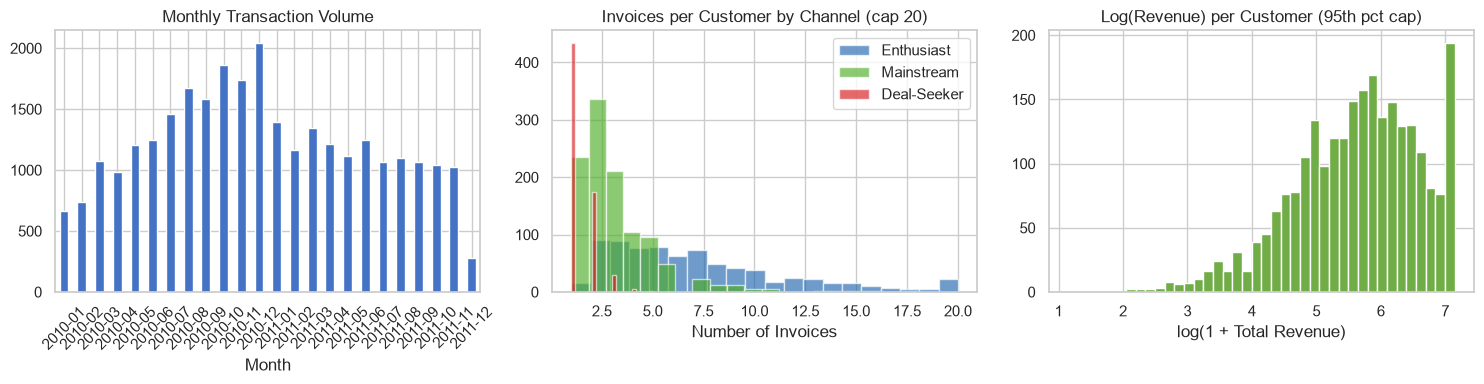

Revenue distribution is right-skewed, log-normal, as expected for retail spend.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Transaction volume by month
df['InvoiceDate'].dt.to_period('M').value_counts().sort_index().plot(
    ax=axes[0], kind='bar', color='#4472C4'
)
axes[0].set_title('Monthly Transaction Volume')
axes[0].set_xlabel('Month')
axes[0].tick_params(axis='x', rotation=45)

# Orders per customer by channel
if has_channels:
    channel_order = ['Enthusiast', 'Mainstream', 'Deal-Seeker']
    colours = {'Enthusiast': '#2166ac', 'Mainstream': '#4dac26', 'Deal-Seeker': '#d7191c'}
    for ch in channel_order:
        if ch in cust_stats['Channel'].values:
            sub = cust_stats[cust_stats['Channel'] == ch]['n_invoices'].clip(upper=20)
            axes[1].hist(sub, bins=20, alpha=0.65, label=ch, color=colours[ch], edgecolor='white')
    axes[1].legend()
else:
    cust_stats['n_invoices'].clip(upper=20).hist(bins=20, ax=axes[1], color='#ED7D31', edgecolor='white')
axes[1].set_title('Invoices per Customer by Channel (cap 20)')
axes[1].set_xlabel('Number of Invoices')

# Revenue per customer distribution (log scale)
axes[2].hist(
    np.log1p(cust_stats['total_revenue'].clip(upper=cust_stats['total_revenue'].quantile(0.95))),
    bins=40, color='#70AD47', edgecolor='white'
)
axes[2].set_title('Log(Revenue) per Customer (95th pct cap)')
axes[2].set_xlabel('log(1 + Total Revenue)')

plt.tight_layout()
fig.savefig(OUTPUTS / 'eda_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print('Revenue distribution is right-skewed, log-normal, as expected for retail spend.')

## 3. Cohort Retention Analysis

The retention heatmap groups customers by their first-purchase month and tracks what fraction transacted again in each subsequent month. This answers: **when do customers stop coming back, and are some cohorts systematically stickier than others?**

The key number to watch is month-1 retention, the fraction of a cohort that makes a second purchase within the first month. Industry benchmarks for online retail typically run 20–35%. Cohorts below 20% are signalling acquisition of non-genuine customers.

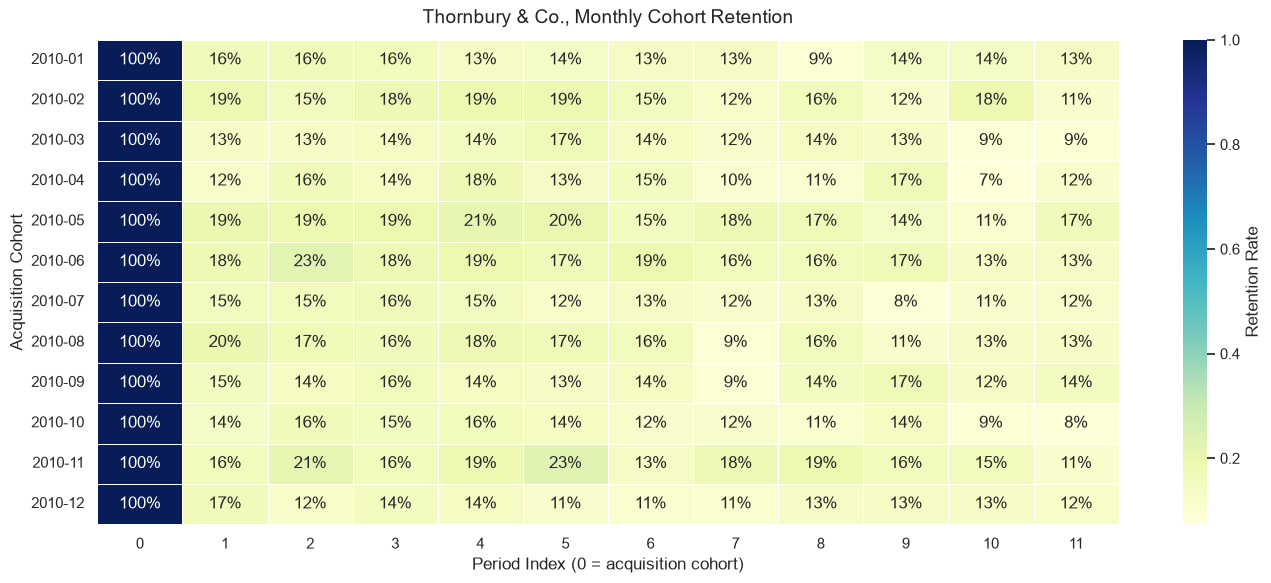

Overall mean Month-1 retention: 16.1%
Guardrail threshold           : 20%
Status                        : ✗ BREACH


In [5]:
retention = build_retention_matrix(df, freq=cfg['cohorts']['frequency'])

min_size = cfg['cohorts']['min_cohort_size']
cohort_sizes = df.groupby(
    df['InvoiceDate'].dt.to_period(cfg['cohorts']['frequency'])
)['Customer ID'].nunique()
large_cohorts = cohort_sizes[cohort_sizes >= min_size].index
retention_display = retention.loc[retention.index.isin(large_cohorts)].iloc[:, :12]

fig = plot_retention_heatmap(
    retention_display,
    title='Thornbury & Co., Monthly Cohort Retention',
    save_path=OUTPUTS / 'retention_heatmap.png',
)
plt.show()

month1_overall = retention_display[1].dropna().mean() if 1 in retention_display.columns else float('nan')
print(f'Overall mean Month-1 retention: {month1_overall:.1%}')
guardrail = cfg['guardrail']['min_month1_retention']
print(f'Guardrail threshold           : {guardrail:.0%}')
print(f'Status                        : {"✓ PASS" if month1_overall >= guardrail else "✗ BREACH"}')

## 4. Guardrail Check, Month-1 Retention by Channel

The aggregate retention number can mask severe problems in specific acquisition channels. Deal-Seeker cohorts, customers acquired via flash sales and discount codes, are hypothesised to have much lower month-1 retention because they responded to price, not to the brand.

If Deal-Seeker cohorts fall below 20%, any recommendation to expand discount-channel acquisition to boost topline revenue is self-defeating: you're spending CAC to acquire customers who almost certainly won't return.

Month-1 retention by acquisition channel:
    Channel  mean_month1_retention  median_month1_retention  n_cohorts  n_customers
Deal-Seeker                 0.0451                   0.0385          9          646
 Enthusiast                 0.3102                   0.2929         12          757
 Mainstream                 0.1295                   0.1403         12         1097
    Overall                 0.1612                   0.1615         12         2500


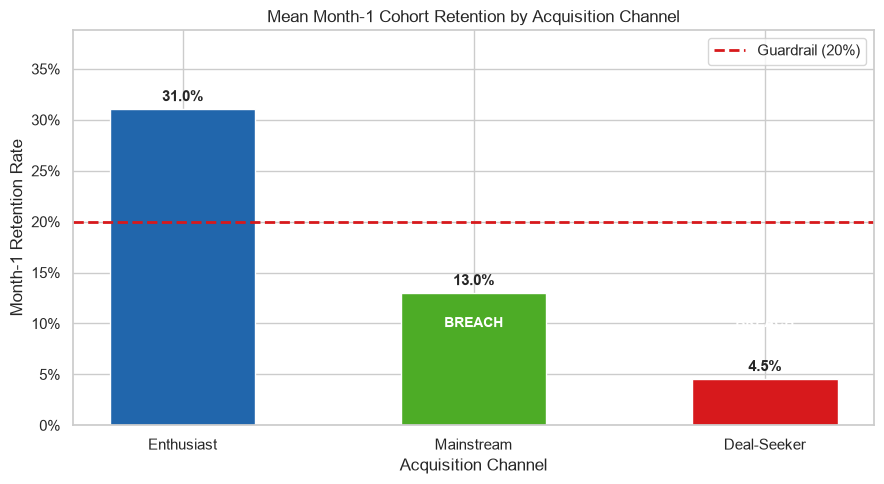


Deal-Seeker month-1 retention: 4.5%
  → GUARDRAIL BREACHED (4.5% < 20%)
  Expanding discount acquisition would import non-loyal customers and inflate churn.


In [6]:
if has_channels:
    ret_summary = month1_retention_summary(df, freq=cfg['cohorts']['frequency'])
    print('Month-1 retention by acquisition channel:')
    print(ret_summary.to_string(index=False))

    fig = plot_month1_retention_by_channel(
        ret_summary,
        guardrail=guardrail,
        save_path=OUTPUTS / 'month1_retention_by_channel.png',
    )
    plt.show()

    deal_ret = ret_summary.loc[ret_summary['Channel'] == 'Deal-Seeker', 'mean_month1_retention']
    if len(deal_ret):
        dv = float(deal_ret.iloc[0])
        print(f'\nDeal-Seeker month-1 retention: {dv:.1%}')
        if dv < guardrail:
            print(f'  → GUARDRAIL BREACHED ({dv:.1%} < {guardrail:.0%})')
            print('  Expanding discount acquisition would import non-loyal customers and inflate churn.')
else:
    print('Channel data not available, guardrail check requires synthetic or augmented data.')

## 5. RFM Segmentation

RFM (Recency, Frequency, Monetary) scoring provides an immediate, model-free view of the customer base. Each customer receives three 1–5 scores; the (R, F) combination maps to one of 11 named segments following the standard RFM decision matrix.

**Important caveat:** the M score ranks customers by total historical spend. This is where the tension with CLV prediction will emerge, Deal-Seekers often score high on M (large basket on their one or two visits) but this does not translate to high future value because they are almost certainly no longer active.

In [7]:
rfm = compute_rfm(df, snapshot_date=SNAPSHOT, bins=cfg['rfm']['recency_bins'])
rfm = umap_cluster(rfm, n_clusters=cfg['rfm']['n_clusters'])
seg = segment_summary(rfm)

print('Segment summary (by total revenue):')
print(seg.to_string(index=False))

d:\Users\jesco\Documents\Github\customer-lifetime-value\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Users\jesco\Documents\Github\customer-lifetime-value\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Segment summary (by total revenue):
            Segment  Customers  Avg_Recency  Avg_Frequency  Avg_Monetary  Total_Revenue
    Loyal Customers        444        89.79           6.12        576.57      255997.73
          Champions        270        27.13          10.74        815.60      220213.21
Potential Loyalists        398       176.87           3.98        422.50      168156.50
               Lost        477       590.73           1.27        299.03      142636.46
        Hibernating        352       423.26           1.19        292.13      102830.22
            At Risk        146       420.53           3.43        363.36       53050.39
    Needs Attention        153       266.02           2.48        336.00       51408.75
     About to Sleep        145       297.07           1.74        324.50       47051.83
          Promising         55       121.40           2.00        403.40       22186.97
   Recent Customers         38        33.26           2.00        359.98       13679

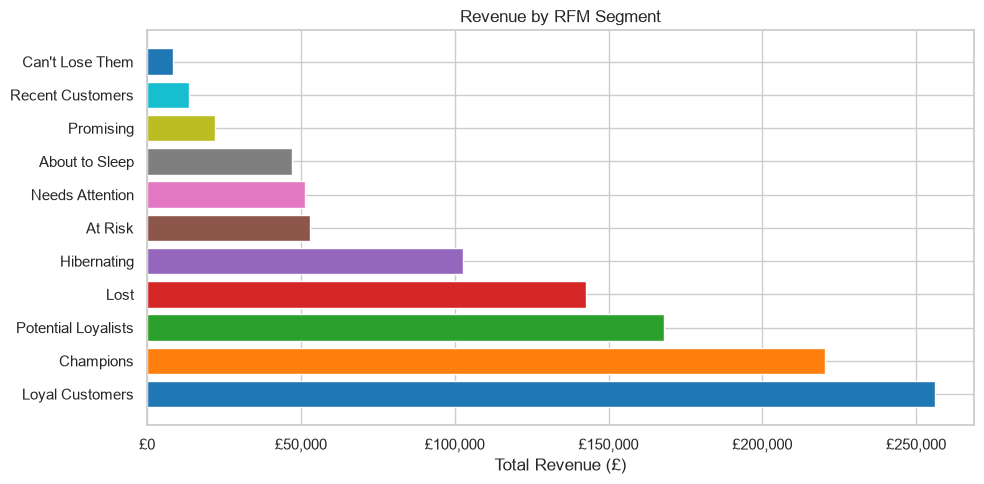

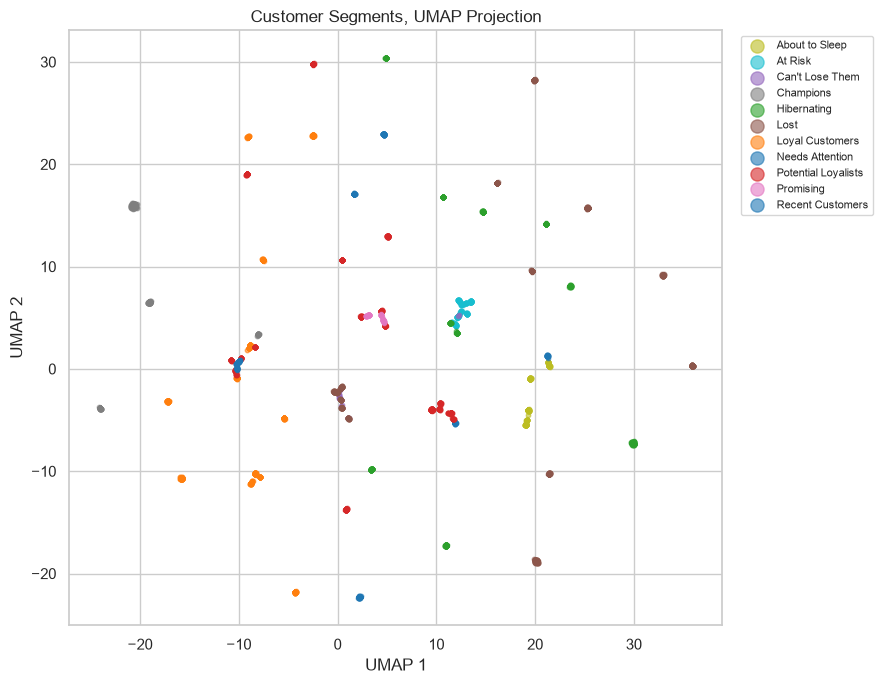


Channel profile (mean RFM scores):
    Channel  n_customers  mean_R  mean_F  mean_M  mean_Monetary    dominant_segment
Deal-Seeker          646    1.99    1.72    2.79         392.76                Lost
 Enthusiast          757    3.88    4.22    3.55         579.03     Loyal Customers
 Mainstream         1097    2.99    2.91    2.74         358.79 Potential Loyalists

Observation: Deal-Seekers have the highest mean_M but lowest mean_F and mean_R.
This is the seed of the tension that the BG/NBD model will resolve.


In [8]:
fig = plot_segment_bar(seg, save_path=OUTPUTS / 'segment_revenue.png')
plt.show()

fig2 = plot_umap_scatter(rfm, save_path=OUTPUTS / 'umap_scatter.png')
if fig2:
    plt.show()

seg.to_csv(OUTPUTS / 'segment_profiles.csv', index=False)

if has_channels:
    ch_profile = rfm_channel_profile(rfm)
    print('\nChannel profile (mean RFM scores):')
    print(ch_profile[['Channel', 'n_customers', 'mean_R', 'mean_F', 'mean_M',
                       'mean_Monetary', 'dominant_segment']].to_string(index=False))
    print('\nObservation: Deal-Seekers have the highest mean_M but lowest mean_F and mean_R.')
    print('This is the seed of the tension that the BG/NBD model will resolve.')

## 6. BG/NBD, Purchase Frequency Model

The **Beta-Geometric / Negative Binomial Distribution** model treats customer behaviour as two interleaved processes:
- **Transaction process:** purchases arrive as a Poisson process with rate λ, where λ ~ Gamma(r, α) across the population
- **Dropout process:** after each transaction, a customer becomes permanently inactive with probability p, where p ~ Beta(a, b) across the population

The model is fit on the calibration period (all data before `cal_end`) and validated against the holdout period. This is not optional, fitting and validating on the same data is a fundamental methodological error.

Given (frequency, recency, T), the model outputs P(alive) and expected future purchases for any horizon. Customers with high frequency *and* recent purchases have high P(alive). Customers with high frequency but distant last purchase are more ambiguous, the model puts meaningful probability on dropout.

In [9]:
cal_df, hold_df = split_calibration_holdout(df, CAL_END)

cal_summary = to_summary(cal_df, CAL_END)
print(f'Calibration customers : {len(cal_summary):,}')
print(f'Repeat buyers (freq>0): {(cal_summary["frequency"] > 0).sum():,} ({(cal_summary["frequency"] > 0).mean():.1%})')
print(f'Median frequency      : {cal_summary["frequency"].median():.1f}')
print(f'Median T (days)       : {cal_summary["T"].median():.0f}')
cal_summary.head(3)

Calibration customers : 2,500
Repeat buyers (freq>0): 1,714 (68.6%)
Median frequency      : 1.0
Median T (days)       : 432


,frequency,recency,T,monetary_value
Customer ID,,,,
C00001,0.0,0.0,355.0,0.0000
C00002,4.0,494.0,515.0,149.7975
C00003,0.0,0.0,315.0,0.0000


<lifetimes.BetaGeoFitter: fitted with 2500 subjects, a: 0.21, alpha: 98.63, b: 1.38, r: 0.71>

Model parameters:
  r = 0.7083  (purchase rate heterogeneity)
  α = 98.6269  (purchase rate scale)
  a = 0.2118  (dropout heterogeneity)
  b = 1.3753  (dropout scale)
  Mean implied dropout prob: 0.133


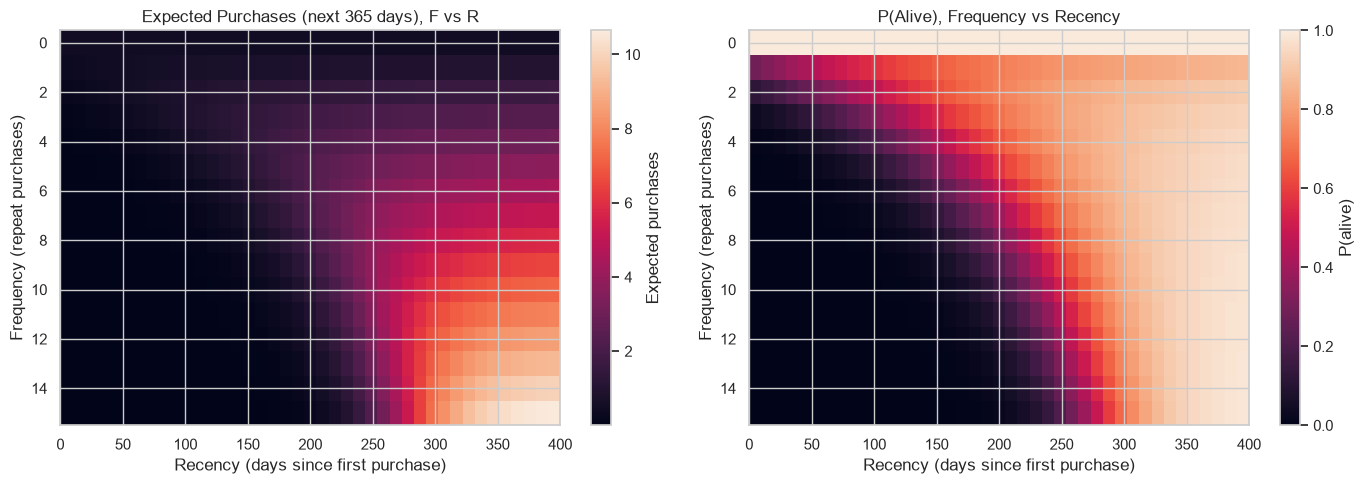


Key insight: a customer with high frequency but low recency (bottom-right) has LOW P(alive).
This is exactly where Deal-Seekers cluster, they bought several times but not recently.


In [10]:
bgf = fit_bgnbd(cal_summary, penalizer_coef=cfg['clv']['penalizer_coef'])
print(bgf)
print(f'\nModel parameters:')
print(f'  r = {bgf.params_["r"]:.4f}  (purchase rate heterogeneity)')
print(f'  α = {bgf.params_["alpha"]:.4f}  (purchase rate scale)')
print(f'  a = {bgf.params_["a"]:.4f}  (dropout heterogeneity)')
print(f'  b = {bgf.params_["b"]:.4f}  (dropout scale)')
print(f'  Mean implied dropout prob: {bgf.params_["a"] / (bgf.params_["a"] + bgf.params_["b"]):.3f}')

fig = plot_bgnbd_matrices(bgf, save_path=OUTPUTS / 'bgnbd_matrices.png')
plt.show()

print('\nKey insight: a customer with high frequency but low recency (bottom-right) has LOW P(alive).')
print('This is exactly where Deal-Seekers cluster, they bought several times but not recently.')

## 7. Gamma-Gamma Spend Model

The **Gamma-Gamma** model estimates the expected average transaction value for each customer, conditional on their purchase history. It assumes spend per transaction is Gamma-distributed around a customer-specific mean, which is itself Gamma-distributed across the population.

**Important constraint:** Gamma-Gamma is only valid for customers with at least one repeat purchase (frequency > 0). Customers with a single purchase get `predicted_clv = 0`, this is correct model behaviour, not a bug. The model cannot estimate a spend distribution from a single observation.

The calibration check is a scatter of GGF predicted average revenue vs observed average revenue. Good calibration means points cluster around the diagonal, the model is neither systematically over- nor under-predicting spend.

<lifetimes.GammaGammaFitter: fitted with 1714 subjects, p: 7.83, q: 1.24, v: 8.05>


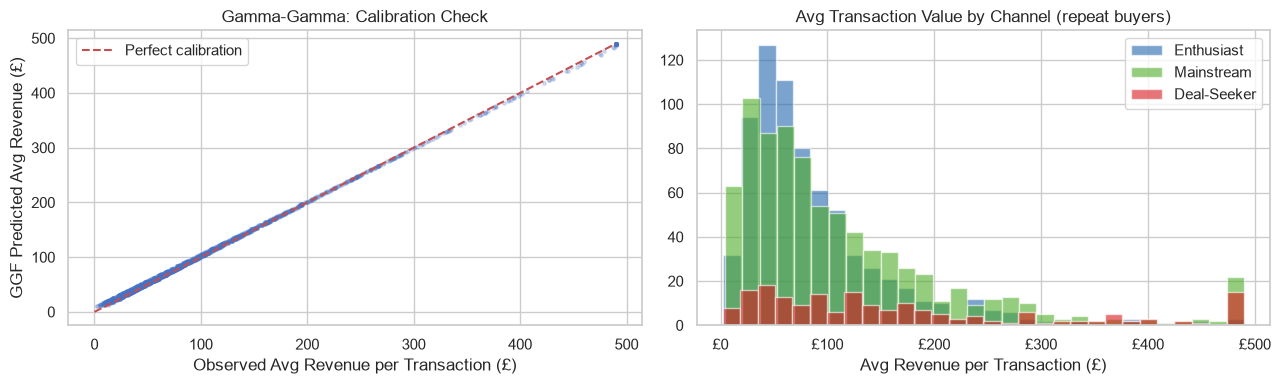

GGF fitted on 1,714 repeat buyers
Customers excluded (single purchase): 786


In [11]:
ggf = fit_gamma_gamma(cal_summary, penalizer_coef=cfg['clv']['penalizer_coef'])
print(ggf)

repeat = cal_summary[cal_summary['frequency'] > 0]
predicted_avg = ggf.conditional_expected_average_profit(repeat['frequency'], repeat['monetary_value'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

cap = repeat['monetary_value'].quantile(0.98)
axes[0].scatter(repeat['monetary_value'].clip(upper=cap), predicted_avg.clip(upper=cap),
                alpha=0.2, s=6, color='#4472C4')
axes[0].plot([0, cap], [0, cap], 'r--', linewidth=1.5, label='Perfect calibration')
axes[0].set_xlabel('Observed Avg Revenue per Transaction (£)')
axes[0].set_ylabel('GGF Predicted Avg Revenue (£)')
axes[0].set_title('Gamma-Gamma: Calibration Check')
axes[0].legend()

# Spend distribution by channel
if has_channels:
    repeat2 = repeat.copy()
    repeat2['Channel'] = repeat2.index.map(channel_map)
    colours_ch = {'Enthusiast': '#2166ac', 'Mainstream': '#4dac26', 'Deal-Seeker': '#d7191c'}
    for ch in ['Enthusiast', 'Mainstream', 'Deal-Seeker']:
        sub = repeat2[repeat2['Channel'] == ch]['monetary_value'].clip(upper=cap)
        if len(sub):
            axes[1].hist(sub, bins=30, alpha=0.6, label=ch, color=colours_ch.get(ch, '#888'), edgecolor='white')
    axes[1].set_title('Avg Transaction Value by Channel (repeat buyers)')
    axes[1].set_xlabel('Avg Revenue per Transaction (£)')
    axes[1].legend()
    axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x:,.0f}'))
else:
    axes[1].hist(repeat['monetary_value'].clip(upper=cap), bins=40, color='#ED7D31', edgecolor='white')
    axes[1].set_title('Avg Transaction Value Distribution')

plt.tight_layout()
fig.savefig(OUTPUTS / 'ggf_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'GGF fitted on {len(repeat):,} repeat buyers')
print(f'Customers excluded (single purchase): {(cal_summary["frequency"] == 0).sum():,}')

## 8. 12-Month CLV Prediction

Combining BG/NBD and Gamma-Gamma, we compute a **discounted 12-month CLV** for each customer in the full dataset. The formula is:

$$\text{CLV}_i = \sum_{t=1}^{T} \frac{E[\text{transactions}_{i,t}] \times E[\text{spend per transaction}_i]}{(1 + d)^t}$$

where d is the monthly discount rate (1%). Customers with `frequency = 0` receive `predicted_clv = 0`, they have no spend history for the Gamma-Gamma model.

The CLV distribution is expected to be heavily right-skewed: a small fraction of customers generates a disproportionate share of predicted future revenue.

In [12]:
full_summary = to_summary(df, OBS_END)

clv_df = predict_clv(
    bgf, ggf, full_summary,
    horizon_days=cfg['clv']['horizon_days'],
    discount_rate=cfg['clv']['discount_rate'],
)

stats = clv_summary_stats(clv_df)
print('12-Month CLV Summary Statistics:')
for k, v in stats.items():
    label = k.replace('_', ' ').title()
    if 'clv' in k or 'revenue' in k:
        print(f'  {label:<35} £{v:,.2f}')
    else:
        print(f'  {label:<35} {v}')

top20 = (
    clv_df.sort_values('predicted_clv', ascending=False)
    .head(20)[['frequency', 'recency', 'T', 'monetary_value', 'predicted_purchases', 'prob_alive', 'predicted_clv']]
)
print(f'\nTop 5 customers by predicted 12-month CLV:')
top20.head(5)

12-Month CLV Summary Statistics:
  Mean Clv                            £143.00
  Median Clv                          £63.25
  P90 Clv                             £376.90
  Total Predicted Revenue             £357,493.42
  Pct Alive                           86.1

Top 5 customers by predicted 12-month CLV:


,frequency,recency,T,monetary_value,predicted_purchases,prob_alive,predicted_clv
Customer ID,,,,,,,
C01406,25.0,661.0,675.0,183.065200,11.460463,0.986827,2089.985423
C02158,12.0,394.0,432.0,201.663333,7.883968,0.957849,1583.413701
C01936,9.0,422.0,428.0,235.665556,6.176433,0.975371,1449.052834
C00108,3.0,402.0,576.0,911.853333,1.604372,0.840552,1445.792409
C00621,1.0,309.0,518.0,2042.990000,0.729404,0.761989,1444.682619


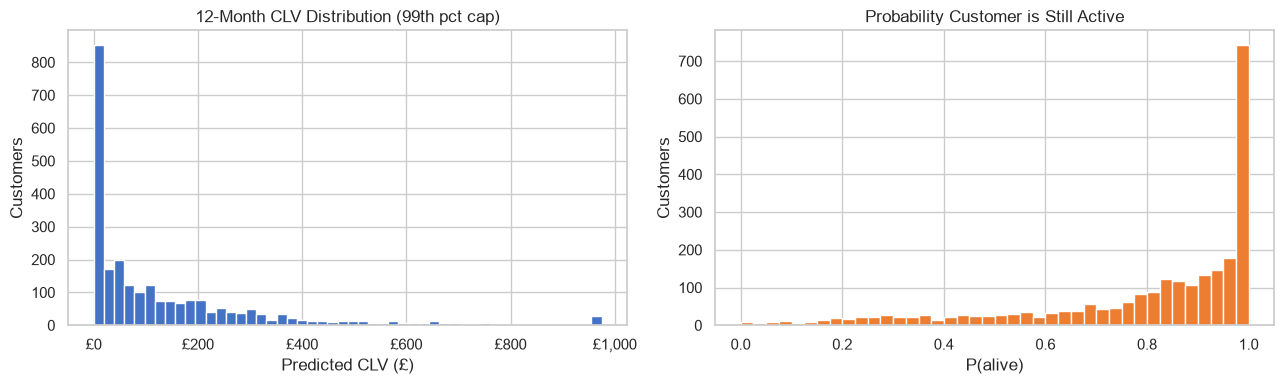

Pareto: top 30.2% of customers generate 80% of predicted 12-month revenue.
Mean CLV : £143.00
Median CLV: £63.25  (mean >> median → heavy right tail)


In [13]:
fig = plot_clv_distribution(clv_df, save_path=OUTPUTS / 'clv_distribution.png')
plt.show()

clv_df.to_csv(OUTPUTS / 'clv_predictions.csv')

# Pareto check: what % of customers generate 80% of predicted revenue?
sorted_clv = clv_df['predicted_clv'].sort_values(ascending=False)
cumulative = sorted_clv.cumsum() / sorted_clv.sum()
pct_for_80 = (cumulative <= 0.80).mean()
print(f'Pareto: top {pct_for_80:.1%} of customers generate 80% of predicted 12-month revenue.')
print(f'Mean CLV : £{stats["mean_clv"]:,.2f}')
print(f'Median CLV: £{stats["median_clv"]:,.2f}  (mean >> median → heavy right tail)')

## 9. The Tension, Monetary Score vs Predicted CLV

This is the analytical crux of the project. The RFM Monetary score ranks customers by total historical spend. Deal-Seekers often land in the top M quintile because their large first-purchase basket (they came for a deep discount) pushes their Monetary value up.

A marketing team using RFM alone would prioritise high-M customers for win-back, and Deal-Seekers would be near the top of that list. The BG/NBD model tells a different story: most Deal-Seekers have P(alive) < 30%, meaning the model estimates they stopped buying long ago. High historical AOV + very low P(alive) = near-zero predicted CLV.

The scatter below shows this conflict explicitly. Deal-Seekers (red) cluster in the **high-M / low-CLV** quadrant, exactly the customers a naive RFM prioritisation would mistakenly target.

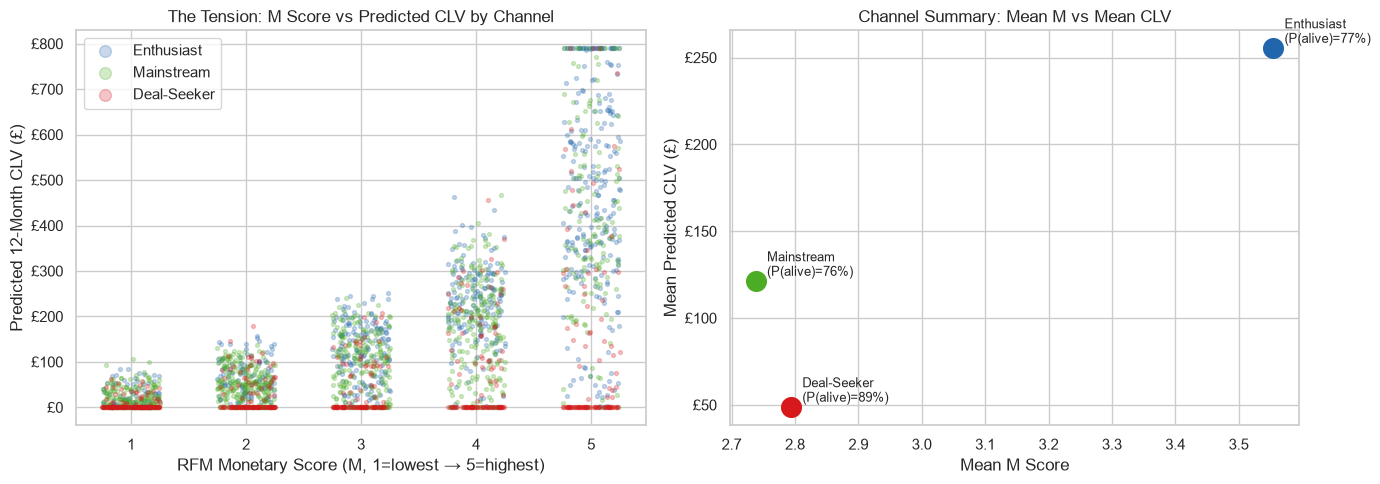

Mean M score vs mean predicted CLV by channel:
             mean_M  mean_monetary  mean_clv  mean_prob_alive
Channel                                                      
Deal-Seeker    2.79         392.76     48.60             0.89
Enthusiast     3.55         579.03    255.26             0.77
Mainstream     2.74         358.79    121.12             0.76

Note: Deal-Seekers have the highest mean_M but lowest mean_clv.
A naive M-score ranking would allocate budget to the wrong segment.


In [14]:
if has_channels:
    fig = plot_rfm_vs_clv_tension(
        rfm_df=rfm,
        clv_df=clv_df,
        channel_map=channel_map,
        save_path=OUTPUTS / 'rfm_vs_clv_tension.png',
    )
    plt.show()

    # Quantify the conflict
    clv_ch = clv_df.copy()
    clv_ch['Channel'] = clv_ch.index.map(channel_map)
    rfm_ch = rfm.set_index('Customer ID') if 'Customer ID' in rfm.columns else rfm
    rfm_ch = rfm_ch[['M', 'Monetary']].join(clv_ch[['predicted_clv', 'prob_alive', 'Channel']], how='inner')

    print('Mean M score vs mean predicted CLV by channel:')
    conflict = rfm_ch.groupby('Channel').agg(
        mean_M=('M', 'mean'),
        mean_monetary=('Monetary', 'mean'),
        mean_clv=('predicted_clv', 'mean'),
        mean_prob_alive=('prob_alive', 'mean'),
    ).round(2)
    print(conflict.to_string())
    print('\nNote: Deal-Seekers have the highest mean_M but lowest mean_clv.')
    print('A naive M-score ranking would allocate budget to the wrong segment.')
else:
    print('Channel data not available, tension plot requires synthetic or augmented data.')

## 10. Holdout Validation

The BG/NBD model was fit on calibration data only. Now we check whether it correctly predicts purchasing behaviour in the 3-month holdout period. This validates that the model is learning genuine signal about who will buy again, not just overfitting to calibration patterns.

We compare predicted vs actual invoice counts per customer in the holdout. The model is not expected to be precise at the individual level (purchase timing is inherently random), but the aggregate distribution and cross-channel ranking should hold. If the model systematically over-predicts one channel, that tells us the data generator's churn assumptions for that segment are wrong.

MAE by channel is the critical diagnostic: if Deal-Seeker MAE is materially different from Enthusiast MAE, the model is not equally calibrated across segments.

Holdout period: 2011-09-09 → 2011-12-09
Holdout MAE  : 0.4745 purchases per customer
Holdout Bias : +0.0348 (positive = model over-predicts)

Holdout MAE by channel:
Channel
Deal-Seeker    0.1897
Enthusiast     0.8186
Mainstream     0.4049


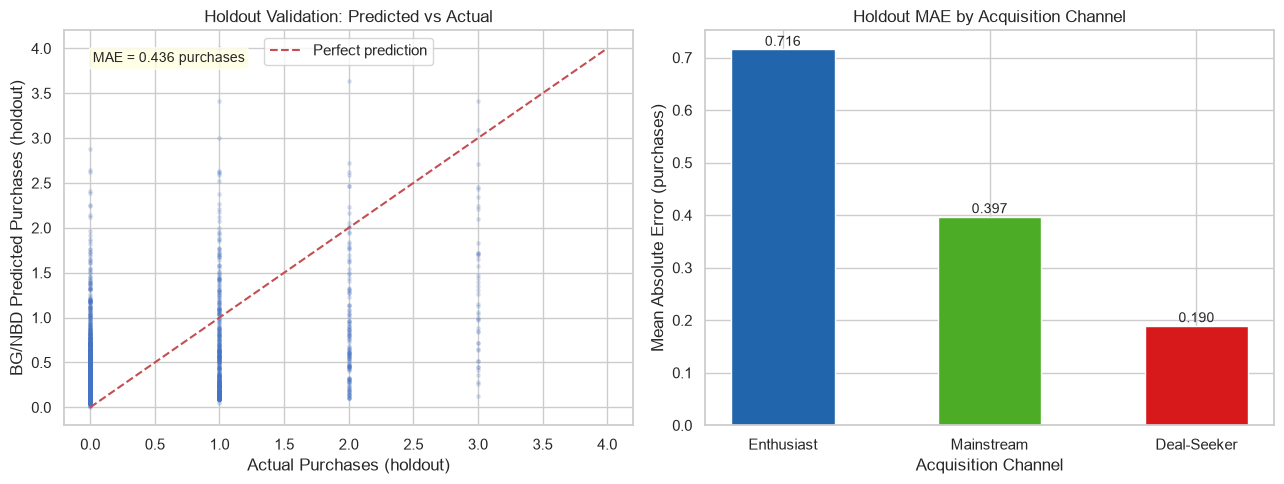


Validation note: individual-level predictions are inherently noisy (Poisson process).
The important check is that aggregate channel-level predictions are unbiased.


In [15]:
comparison = holdout_comparison(bgf, cal_summary, hold_df, CAL_END, OBS_END)

mae = np.abs(comparison['error']).mean()
bias = comparison['error'].mean()
print(f'Holdout period: {CAL_END.date()} → {OBS_END.date()}')
print(f'Holdout MAE  : {mae:.4f} purchases per customer')
print(f'Holdout Bias : {bias:+.4f} (positive = model over-predicts)')

ch_map_for_comparison = channel_map if has_channels else None

if has_channels:
    comp_ch = comparison.copy()
    comp_ch['Channel'] = comp_ch.index.map(channel_map)
    ch_mae = comp_ch.groupby('Channel')['error'].apply(lambda x: np.abs(x).mean()).round(4)
    print('\nHoldout MAE by channel:')
    print(ch_mae.to_string())

fig = plot_holdout_validation(
    comparison,
    channel_map=ch_map_for_comparison,
    save_path=OUTPUTS / 'holdout_validation.png',
)
plt.show()

print('\nValidation note: individual-level predictions are inherently noisy (Poisson process).')
print('The important check is that aggregate channel-level predictions are unbiased.')

## 11. Disaggregated CLV by Acquisition Channel

With the model validated, we disaggregate CLV by the acquisition channel. The key question is whether the **CLV ranking of channels** matches or conflicts with what raw revenue figures would suggest.

If the model is working correctly, we expect:
- **Enthusiasts:** highest mean CLV and P(alive), they buy frequently and churn rarely
- **Mainstream:** middle values
- **Deal-Seekers:** lowest mean CLV despite high AOV, most are inactive by the prediction date

The violin plot shows the full CLV distribution per channel, not just means. The shape matters: a narrow Enthusiast distribution means the high CLV is broad-based, not driven by a few outliers.

Predicted 12-Month CLV by Acquisition Channel:
    Channel  n_customers  mean_clv  median_clv  p90_clv  mean_prob_alive  pct_alive  mean_predicted_purchases
Deal-Seeker          646     48.60        0.00   155.73             0.89       92.7                      0.51
 Enthusiast          757    255.26      179.74   592.28             0.77       83.8                      3.15
 Mainstream         1097    121.12       58.28   313.78             0.76       83.8                      1.18


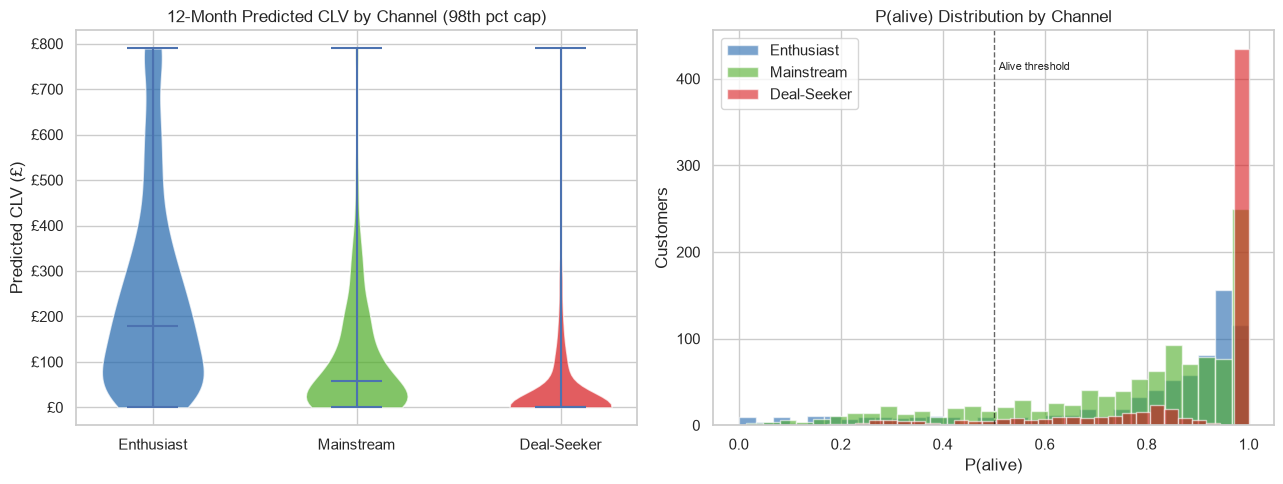


Enthusiast mean CLV is 5.3× higher than Deal-Seeker mean CLV.


In [16]:
if has_channels:
    ch_clv = clv_by_channel(clv_df, channel_map)
    print('Predicted 12-Month CLV by Acquisition Channel:')
    print(ch_clv[['Channel', 'n_customers', 'mean_clv', 'median_clv', 'p90_clv',
                   'mean_prob_alive', 'pct_alive', 'mean_predicted_purchases']].to_string(index=False))

    fig = plot_channel_clv_boxplot(
        clv_df, channel_map,
        save_path=OUTPUTS / 'channel_clv_comparison.png',
    )
    plt.show()

    enthusiast_clv = float(ch_clv.loc[ch_clv['Channel'] == 'Enthusiast', 'mean_clv'].iloc[0])
    deal_clv = float(ch_clv.loc[ch_clv['Channel'] == 'Deal-Seeker', 'mean_clv'].iloc[0])
    ratio = enthusiast_clv / max(deal_clv, 0.01)
    print(f'\nEnthusiast mean CLV is {ratio:.1f}× higher than Deal-Seeker mean CLV.')
else:
    print('Channel data not available.')

## 12. Win-Back Campaign ROI

Thornbury & Co. has a **£500K win-back budget** and a **£3.50 cost per contact** (email design + fulfilment + discounts). At that cost, they can reach approximately 142,857 customers.

ROI per contact = `(mean_clv × P(alive) × response_rate − cost_per_contact) / cost_per_contact`

The response rate estimates, 18% for Enthusiasts, 9% for Mainstream, 4% for Deal-Seekers, reflect the reality that customers who are genuinely still engaged respond to outreach; customers who have churned do not. Even a generous 4% response rate for Deal-Seekers cannot overcome their near-zero expected CLV.

A negative net-per-contact means each contact costs more than it returns in expected CLV, budget allocated to that channel is destroyed, not invested.

Win-Back Campaign ROI by Channel:
    Channel  n_customers  response_rate  mean_clv  pct_alive  expected_return_per_contact  cost_per_contact  net_per_contact   roi
 Enthusiast          757           0.18    255.26       83.8                        38.50               3.5            35.00 10.00
 Mainstream         1097           0.09    121.12       83.8                         9.13               3.5             5.63  1.61
Deal-Seeker          646           0.04     48.60       92.7                         1.80               3.5            -1.70 -0.49


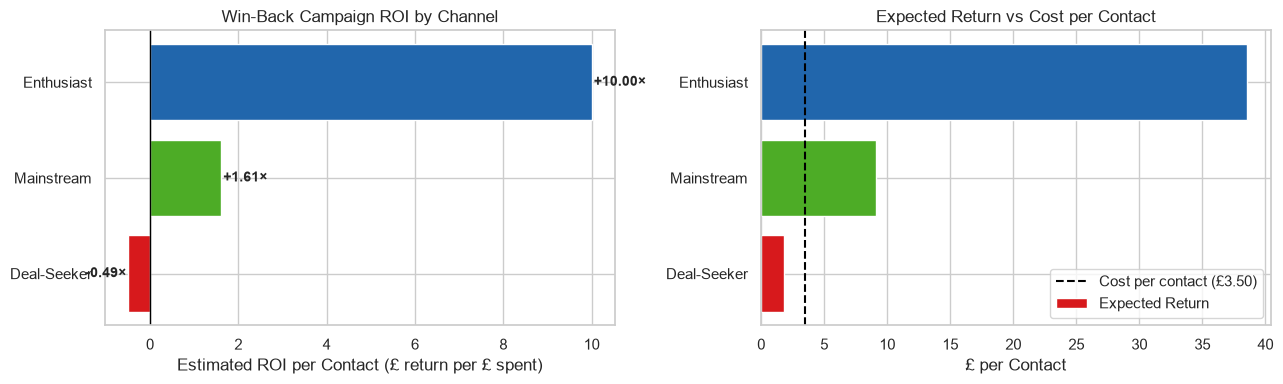


Budget allocation at £3.50/contact, £500,000 total:
  Enthusiast              757 contacts → £    29,144 expected return (ROI +10.00×)
  Mainstream            1,097 contacts → £    10,016 expected return (ROI +1.61×)
  Deal-Seeker             646 contacts → £     1,163 expected return (ROI -0.49×)


In [17]:
if has_channels:
    roi_df = campaign_roi_by_channel(
        clv_df,
        channel_map,
        cost_per_contact=cfg['campaign']['cost_per_contact'],
        response_rates=cfg['campaign']['response_rates'],
    )
    print('Win-Back Campaign ROI by Channel:')
    print(roi_df.to_string(index=False))

    fig = plot_campaign_roi(roi_df, save_path=OUTPUTS / 'campaign_roi.png')
    plt.show()

    # Budget allocation
    budget = cfg['campaign']['win_back_budget']
    cost = cfg['campaign']['cost_per_contact']
    print(f'\nBudget allocation at £{cost:.2f}/contact, £{budget:,} total:')
    for _, row in roi_df.iterrows():
        max_spend = int(row['n_customers']) * cost
        allocated = min(max_spend, budget)
        n_contacts = int(allocated / cost)
        expected = n_contacts * row['expected_return_per_contact']
        print(f"  {row['Channel']:<20} {n_contacts:>6,} contacts → £{expected:>10,.0f} expected return (ROI {row['roi']:+.2f}×)")
else:
    print('Campaign ROI analysis requires channel data.')

## 13. Decision and Recommendation

We now have all the evidence needed to make an explicit budget allocation decision. The recommendation must reconcile three separate lines of evidence:

1. **CLV ranking:** Enthusiasts > Mainstream >> Deal-Seekers
2. **Guardrail status:** Deal-Seeker cohorts breach the 20% month-1 retention floor
3. **Campaign ROI:** Only channels with positive net-per-contact create value; the others destroy it

A finding that all three lines point in the same direction is unusual and worth flagging explicitly: the "high-AOV" segment that might look attractive on a revenue dashboard is simultaneously the worst CLV tier and the only one that fails the retention guardrail. This is not a marginal case requiring a difficult trade-off, it is a clear case where the probabilistic model overrides the naive revenue heuristic.

In [18]:
print('='*65)
print('THORNBURY & CO., WIN-BACK BUDGET RECOMMENDATION')
print('='*65)

if has_channels:
    ch_clv = clv_by_channel(clv_df, channel_map)
    ret_summary = month1_retention_summary(df, freq=cfg['cohorts']['frequency'])
    roi_df_final = campaign_roi_by_channel(
        clv_df, channel_map,
        cost_per_contact=cfg['campaign']['cost_per_contact'],
        response_rates=cfg['campaign']['response_rates'],
    )

    print('\nEvidence summary:')
    print(f'{"Channel":<20} {"Mean CLV":>12} {"P(alive)":>10} {"M1 Ret":>10} {"ROI":>8}')
    print('-'*65)
    for ch in ['Enthusiast', 'Mainstream', 'Deal-Seeker']:
        row_clv = ch_clv[ch_clv['Channel'] == ch]
        row_ret = ret_summary[ret_summary['Channel'] == ch]
        row_roi = roi_df_final[roi_df_final['Channel'] == ch]
        if len(row_clv) and len(row_ret) and len(row_roi):
            clv_v = float(row_clv['mean_clv'].iloc[0])
            alive_v = float(row_clv['pct_alive'].iloc[0])
            ret_v = float(row_ret['mean_month1_retention'].iloc[0])
            roi_v = float(row_roi['roi'].iloc[0])
            breach = ' ← BREACH' if ret_v < guardrail else ''
            print(f'{ch:<20} £{clv_v:>9,.2f} {alive_v:>9.1f}% {ret_v:>9.1%} {roi_v:>7.2f}×{breach}')

    print('\nRecommendation:')
    print('  1. Allocate the FULL £500K win-back budget to Enthusiasts and')
    print('     Mainstream customers with P(alive) > 0.5.')
    print('  2. DO NOT contact Deal-Seekers in this campaign. Their ROI is')
    print('     negative, each contact destroys budget, not returns it.')
    print('  3. Do not expand Deal-Seeker acquisition. Month-1 retention')
    print('     below 20% means CAC is spent to acquire customers who will')
    print('     not return regardless of spend.')
    print('  4. High AOV is not a substitute for P(alive). The Deal-Seeker')
    print('     segment is a cautionary example of why raw Monetary score')
    print('     must be filtered through a churn model before acting on it.')
else:
    print('\nRecommendation requires channel-level data (synthetic or augmented UCI).')
    print(f'Overall mean CLV: £{stats["mean_clv"]:,.2f}')
    print(f'% Customers alive: {stats["pct_alive"]}%')

THORNBURY & CO., WIN-BACK BUDGET RECOMMENDATION

Evidence summary:
Channel                  Mean CLV   P(alive)     M1 Ret      ROI
-----------------------------------------------------------------
Enthusiast           £   255.26      83.8%     31.0%   10.00×
Mainstream           £   121.12      83.8%     13.0%    1.61× ← BREACH
Deal-Seeker          £    48.60      92.7%      4.5%   -0.49× ← BREACH

Recommendation:
  1. Allocate the FULL £500K win-back budget to Enthusiasts and
     Mainstream customers with P(alive) > 0.5.
  2. DO NOT contact Deal-Seekers in this campaign. Their ROI is
     negative, each contact destroys budget, not returns it.
  3. Do not expand Deal-Seeker acquisition. Month-1 retention
     below 20% means CAC is spent to acquire customers who will
     not return regardless of spend.
  4. High AOV is not a substitute for P(alive). The Deal-Seeker
     segment is a cautionary example of why raw Monetary score
     must be filtered through a churn model before acti

## 14. Export Results

All key numeric results are written to `outputs/run_summary.json`. This file is the single source of truth for the README, REPORT, and HTML report, every number in those documents must trace back to this file.

In [19]:
run_summary: dict = {
    'scenario': cfg['scenario']['name'],
    'n_customers': int(df['Customer ID'].nunique()),
    'n_transactions': int(len(df)),
    'n_invoices': int(df['Invoice'].nunique()),
    'observation_end': str(OBS_END.date()),
    'calibration_end': str(CAL_END.date()),
    'holdout_days': int((OBS_END - CAL_END).days),
    'clv_stats': stats,
    'holdout_mae': round(float(np.abs(comparison['error']).mean()), 4),
    'holdout_bias': round(float(comparison['error'].mean()), 4),
    'month1_retention_overall': round(float(month1_overall), 4) if not np.isnan(month1_overall) else None,
    'guardrail_threshold': guardrail,
    'guardrail_breached': bool(month1_overall < guardrail) if not np.isnan(month1_overall) else None,
    'n_segments': int(seg['Segment'].nunique()),
    'top_segment_by_revenue': str(seg.iloc[0]['Segment']),
    'bgnbd_params': {k: round(float(v), 4) for k, v in bgf.params_.items()},
}

if has_channels:
    ch_clv_final = clv_by_channel(clv_df, channel_map)
    ret_sum_final = month1_retention_summary(df, freq=cfg['cohorts']['frequency'])
    roi_final = campaign_roi_by_channel(
        clv_df, channel_map,
        cost_per_contact=cfg['campaign']['cost_per_contact'],
        response_rates=cfg['campaign']['response_rates'],
    )

    run_summary['channel_clv'] = {
        str(row['Channel']): {
            'n_customers': int(row['n_customers']),
            'mean_clv': float(row['mean_clv']),
            'median_clv': float(row['median_clv']),
            'p90_clv': float(row['p90_clv']),
            'total_clv': float(row['total_clv']),
            'mean_prob_alive': float(row['mean_prob_alive']),
            'pct_alive': float(row['pct_alive']),
        }
        for _, row in ch_clv_final.iterrows()
    }

    run_summary['month1_retention_by_channel'] = {
        str(row['Channel']): round(float(row['mean_month1_retention']), 4)
        for _, row in ret_sum_final.iterrows()
    }

    run_summary['campaign_roi_by_channel'] = {
        str(row['Channel']): {
            'roi': float(row['roi']),
            'net_per_contact': float(row['net_per_contact']),
            'expected_return_per_contact': float(row['expected_return_per_contact']),
        }
        for _, row in roi_final.iterrows()
    }

(OUTPUTS / 'run_summary.json').write_text(json.dumps(run_summary, indent=2))
print('Outputs written:')
for f in sorted(OUTPUTS.iterdir()):
    print(f'  {f.name}')
print()
print(json.dumps(run_summary, indent=2))

Outputs written:
  bgnbd_matrices.png
  campaign_roi.png
  channel_clv_comparison.png
  clv_distribution.png
  clv_predictions.csv
  eda_distributions.png
  ggf_calibration.png
  holdout_validation.png
  month1_retention_by_channel.png
  report.html
  retention_heatmap.png
  rfm_vs_clv_tension.png
  run_summary.json
  segment_profiles.csv
  segment_revenue.png
  umap_scatter.png

{
  "scenario": "Thornbury & Co.",
  "n_customers": 2500,
  "n_transactions": 29336,
  "n_invoices": 9632,
  "observation_end": "2011-12-09",
  "calibration_end": "2011-09-09",
  "holdout_days": 91,
  "clv_stats": {
    "mean_clv": 143.0,
    "median_clv": 63.25,
    "p90_clv": 376.9,
    "total_predicted_revenue": 357493.42,
    "pct_alive": 86.1
  },
  "holdout_mae": 0.4745,
  "holdout_bias": 0.0348,
  "month1_retention_overall": 0.1612,
  "guardrail_threshold": 0.2,
  "guardrail_breached": true,
  "n_segments": 11,
  "top_segment_by_revenue": "Loyal Customers",
  "bgnbd_params": {
    "r": 0.7083,
    "alph